# 06. Проверка гипотез (этап 7)

| | Гипотеза | Что сравниваем |
|---|---|---|
| **H1** | Однокомнатные квартиры доходнее трёхкомнатных | чистая доходность 1-к против 3-к |
| **H2** | Правый берег доходнее левого | чистая доходность правого и левого берега, внутри каждой группы комнат |
| **H3** | Крайние этажи дешевле средних минимум на 5% | цена за м² относительно средних этажей того же сегмента |

**Методика.**
- Распределения доходности и цен скошены (этап 4), поэтому используем непараметрический **U-критерий Манна–Уитни**.
  Гипотезы направленные, поэтому тесты **односторонние**.
- Уровень значимости **α = 0,05**. Гипотез три, поэтому дополнительно проверяем поправку Бонферрони: α = 0,05 / 3 ≈ 0,017.
- Размер эффекта показываем как **разницу медиан** с **95% бутстрэп-интервалом** (5000 повторов) —
  p-value говорит, есть ли разница, а интервал — насколько она велика.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
ALPHA = 0.05
ALPHA_BONF = ALPHA / 3
rng = np.random.default_rng(42)

df = pd.read_pickle("data/clean_flats.pkl")
inv = pd.read_pickle("data/investment_metrics.pkl")   # чистая доходность каждой квартиры (этап 5)
for frame in (df, inv):
    for col in ["district", "bank", "floor_type", "building_height"]:
        if col in frame:
            frame[col] = frame[col].astype(str)
    frame["rooms_grp"] = frame["rooms_grp"].astype(int)

def bootstrap_median_diff(a, b, n=5000):
    a, b = np.asarray(a), np.asarray(b)
    diffs = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)]
    return np.percentile(diffs, [2.5, 97.5])

results = []
def report(name, a, b, alternative, label_a, label_b, fmt="{:.2%}"):
    p = mannwhitneyu(a, b, alternative=alternative).pvalue
    lo, hi = bootstrap_median_diff(a, b)
    diff = np.median(a) - np.median(b)
    results.append({"гипотеза": name, "группа A": label_a, "n A": len(a), "медиана A": np.median(a),
                    "группа B": label_b, "n B": len(b), "медиана B": np.median(b),
                    "разница медиан": diff, "ДИ 95% низ": lo, "ДИ 95% верх": hi, "p-value": p})
    print(f"{name}: {label_a} {fmt.format(np.median(a))} (n={len(a)}) vs {label_b} {fmt.format(np.median(b))} (n={len(b)})")
    print(f"   разница медиан {diff:+.2%}, 95% ДИ [{lo:+.2%}; {hi:+.2%}], p-value = {p:.2e} "
          f"→ {'H₀ отвергаем' if p < ALPHA_BONF else 'H₀ не отвергаем'}")
    return p

## H1. Однокомнатные квартиры доходнее трёхкомнатных

- **H₀:** распределения чистой доходности 1- и 3-комнатных квартир одинаковы.
- **H₁:** доходность однушек выше (односторонний тест).

**Важная оговорка.** Доходность квартиры на продажу мы оцениваем через медианную аренду её сегмента (этап 5),
поэтому тест частично опирается на нашу же конструкцию. Чтобы проверка была честной, отдельно проверяем
**механизм на сырых данных**: аренда за м² у однушек выше, а цена продажи за м² — нет.

In [2]:
a = inv.loc[inv["rooms_grp"] == 1, "net_yield"]
b = inv.loc[inv["rooms_grp"] == 3, "net_yield"]
report("H1", a, b, "greater", "1-комнатные", "3-комнатные")

print("\nМеханизм на сырых объявлениях:")
rent = df[(df["deal"] == "rent") & (df["district"] != "Не указан")]
sale = df[(df["deal"] == "sale") & (df["district"] != "Не указан")]
r1, r3 = rent.loc[rent["rooms_grp"] == 1, "price_per_m2"], rent.loc[rent["rooms_grp"] == 3, "price_per_m2"]
s1, s3 = sale.loc[sale["rooms_grp"] == 1, "price_per_m2"], sale.loc[sale["rooms_grp"] == 3, "price_per_m2"]
print(f"   аренда за м²: 1-к {r1.median():,.0f} ₸ vs 3-к {r3.median():,.0f} ₸ "
      f"({r1.median() / r3.median() - 1:+.0%}), p = {mannwhitneyu(r1, r3, alternative='greater').pvalue:.1e}")
print(f"   продажа за м²: 1-к {s1.median():,.0f} ₸ vs 3-к {s3.median():,.0f} ₸ "
      f"({s1.median() / s3.median() - 1:+.0%}), p = {mannwhitneyu(s1, s3).pvalue:.3f} (двусторонний)")

print("\nВнутри каждого района (1-к против 3-к):")
by_district = []
for d, g in inv.groupby("district"):
    x, y = g.loc[g["rooms_grp"] == 1, "net_yield"], g.loc[g["rooms_grp"] == 3, "net_yield"]
    if len(x) >= 10 and len(y) >= 10:
        by_district.append({"район": d, "n 1-к": len(x), "n 3-к": len(y),
                            "разница медиан": x.median() - y.median(),
                            "p-value": mannwhitneyu(x, y, alternative="greater").pvalue})
display(pd.DataFrame(by_district).style.format({"разница медиан": "{:+.2%}", "p-value": "{:.4f}"}))

H1: 1-комнатные 9.34% (n=627) vs 3-комнатные 7.82% (n=915)
   разница медиан +1.52%, 95% ДИ [+1.25%; +1.88%], p-value = 1.59e-42 → H₀ отвергаем

Механизм на сырых объявлениях:
   аренда за м²: 1-к 5,952 ₸ vs 3-к 5,000 ₸ (+19%), p = 5.4e-19
   продажа за м²: 1-к 613,648 ₸ vs 3-к 633,333 ₸ (-3%), p = 0.010 (двусторонний)

Внутри каждого района (1-к против 3-к):


,район,n 1-к,n 3-к,разница медиан,p-value
0,Алматинский,82,129,+1.55%,0.0000
1,Байконур,18,31,+1.17%,0.0010
2,Есильский,155,302,+1.17%,0.0000
3,Нура,191,268,+1.78%,0.0000
4,Сарайшык,85,110,+1.04%,0.0332
5,Сарыарка,96,75,+1.90%,0.0000


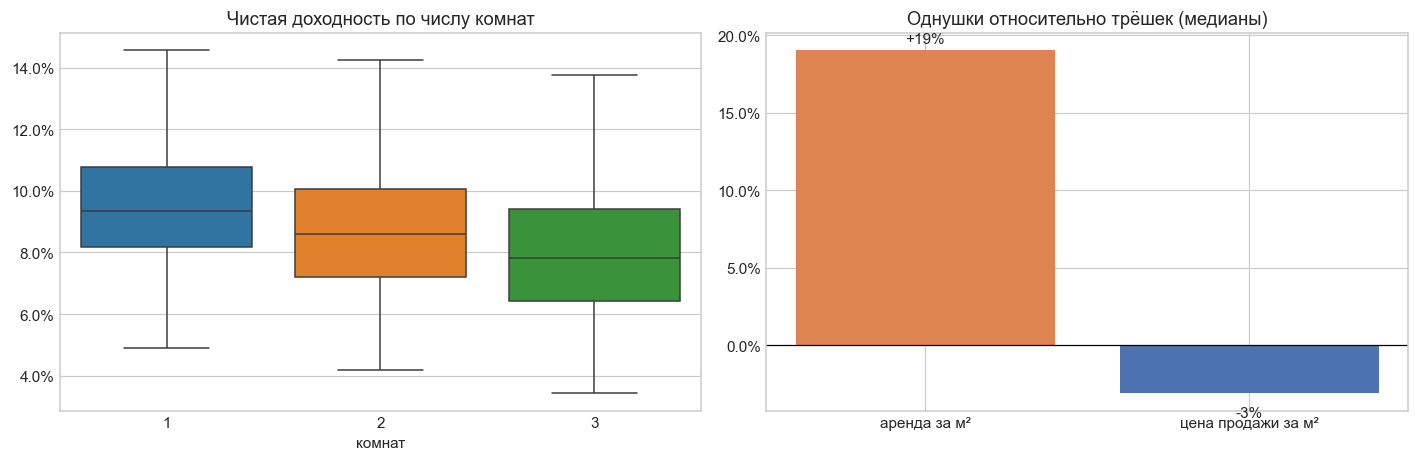

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
plot = inv[inv["rooms_grp"].isin([1, 2, 3])].assign(комнат=lambda x: x["rooms_grp"].astype(str))
sns.boxplot(data=plot, x="комнат", y="net_yield", order=["1", "2", "3"], hue="комнат", hue_order=["1", "2", "3"],
            legend=False, showfliers=False, ax=axes[0])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set(title="Чистая доходность по числу комнат", xlabel="комнат", ylabel="")

mech = pd.Series({"аренда за м²": r1.median() / r3.median() - 1, "цена продажи за м²": s1.median() / s3.median() - 1})
axes[1].bar(mech.index, mech.values, color=["#DD8452", "#4C72B0"])
for i, v in enumerate(mech.values):
    axes[1].text(i, v + (0.005 if v >= 0 else -0.015), f"{v:+.0%}", ha="center")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set(title="Однушки относительно трёшек (медианы)", ylabel="")
plt.tight_layout(); plt.show()

**Вывод по H1 — подтверждается.**
- Медианная чистая доходность однушек — **≈9,3%**, трёшек — **≈7,8%**; разница **≈+1,5 п.п.**
  (95% ДИ: от +1,3 до +1,9 п.п.), p-value ≪ 0,001.
- Эффект есть **в каждом из 6 районов** (+1,0…+1,9 п.п., везде p < 0,05).
- Механизм подтверждается на сырых данных, без наших расчётов доходности: однушка сдаётся **на ≈19% дороже за м²**,
  а продаётся даже **на ≈3% дешевле за м²**, чем трёшка.

**Что делать бизнесу:** клиентам с бюджетом до 25 млн ₸ по умолчанию предлагать однушки; клиентам с бюджетом
45–50 млн ₸ — рассматривать **две однушки вместо одной трёшки**: доходность выше, а риск простоя распределён между двумя квартирами.

## H2. Правый берег доходнее левого

- **H₀:** распределения чистой доходности на правом и левом берегу одинаковы.
- **H₁:** на правом берегу доходность выше.

На правом берегу больше однушек, а они доходнее (H1). Чтобы разница не объяснялась составом квартир,
дополнительно сравниваем берега **внутри каждой группы комнат**.

H2: Правый берег 9.26% (n=1087) vs Левый берег 8.05% (n=1791)
   разница медиан +1.21%, 95% ДИ [+0.97%; +1.37%], p-value = 4.64e-39 → H₀ отвергаем


,комнат,n правый,n левый,медиана правый,медиана левый,разница,p-value
0,1,281,346,10.11%,8.89%,+1.22%,5.7e-11
1,2,388,676,9.31%,8.26%,+1.04%,2.3e-13
2,3,345,570,8.52%,7.32%,+1.21%,1.5e-12
3,4+,73,199,8.96%,7.35%,+1.61%,1.4e-05


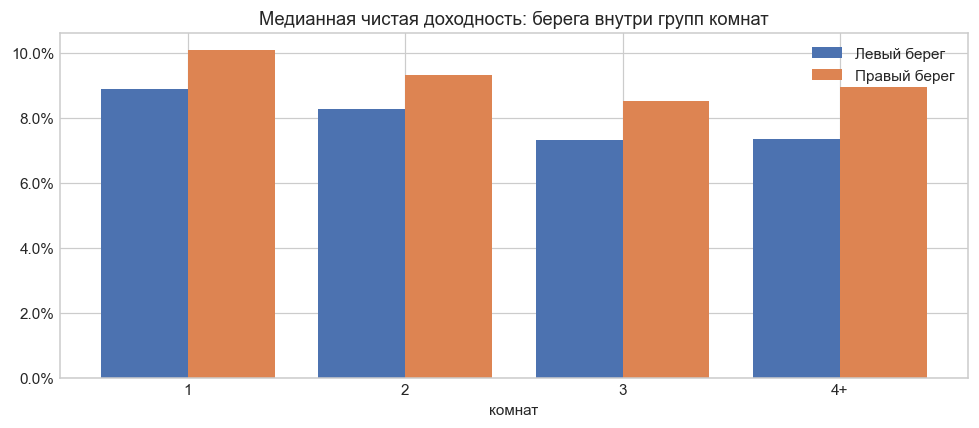

In [4]:
a = inv.loc[inv["bank"] == "Правый берег", "net_yield"]
b = inv.loc[inv["bank"] == "Левый берег", "net_yield"]
report("H2", a, b, "greater", "Правый берег", "Левый берег")

by_rooms = []
for k, g in inv.groupby("rooms_grp"):
    x, y = g.loc[g["bank"] == "Правый берег", "net_yield"], g.loc[g["bank"] == "Левый берег", "net_yield"]
    by_rooms.append({"комнат": "4+" if k == 4 else str(k), "n правый": len(x), "n левый": len(y),
                     "медиана правый": x.median(), "медиана левый": y.median(),
                     "разница": x.median() - y.median(),
                     "p-value": mannwhitneyu(x, y, alternative="greater").pvalue})
by_rooms = pd.DataFrame(by_rooms)
display(by_rooms.style.format({"медиана правый": "{:.2%}", "медиана левый": "{:.2%}",
                               "разница": "{:+.2%}", "p-value": "{:.1e}"}))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(by_rooms))
ax.bar(x - 0.2, by_rooms["медиана левый"], 0.4, label="Левый берег", color="#4C72B0")
ax.bar(x + 0.2, by_rooms["медиана правый"], 0.4, label="Правый берег", color="#DD8452")
ax.set_xticks(x, by_rooms["комнат"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Медианная чистая доходность: берега внутри групп комнат", xlabel="комнат")
ax.legend()
plt.tight_layout(); plt.show()

**Вывод по H2 — подтверждается.**
- Медианная чистая доходность на правом берегу — **≈9,3%**, на левом — **≈8,0%**; разница **≈+1,2 п.п.**
  (95% ДИ: от +1,0 до +1,4 п.п.), p-value ≪ 0,001.
- Преимущество правого берега сохраняется **в каждой группе комнат** (+1,0…+1,6 п.п., везде p < 0,001) —
  значит, дело не в том, что на правом берегу больше однушек.

**Что делать бизнесу:** клиентам, для которых важна окупаемость, предлагать правый берег (Сарыарка, Алматинский,
Сарайшык). Левый берег — тем, кому важнее престиж района и ликвидность при перепродаже: эти выгоды
доходность не измеряет, и их стоит обсуждать с клиентом отдельно.

## H3. Первый и последний этажи дешевле минимум на 5%

- **H₀:** дисконт крайних этажей к средним **не больше 5%**.
- **H₁:** крайние этажи дешевле средних **больше чем на 5%**.

Сравниваем не «сырые» цены, а **отклонение цены за м² от медианы средних этажей в том же сегменте**
(район × комнаты × высотность дома). Так разница не объясняется тем, что на первых этажах чаще
старые малоэтажные дома. Для порога 5% проверяем сдвинутый тест: сравниваем `отклонение + 5%` со средними этажами.

In [5]:
s = df[(df["deal"] == "sale") & (df["district"] != "Не указан") & (df["floor_type"] != "Не указан")].copy()
seg = ["district", "rooms_grp", "building_height"]
mid = s[s["floor_type"] == "Средний"].groupby(seg)["price_per_m2"].median().rename("mid_ppm2")
s = s.join(mid, on=seg)
s["rel"] = s["price_per_m2"] / s["mid_ppm2"] - 1
s = s.dropna(subset=["rel"])

middle = s.loc[s["floor_type"] == "Средний", "rel"]
for ft in ["Первый", "Последний"]:
    report(f"H3 ({ft.lower()})", s.loc[s["floor_type"] == ft, "rel"], middle, "less", ft, "Средний")

edge = s.loc[s["floor_type"].isin(["Первый", "Последний"]), "rel"]
report("H3 (крайние вместе)", edge, middle, "less", "Крайние", "Средний")

p_5 = mannwhitneyu(edge + 0.05, middle, alternative="less").pvalue
print(f"\nПроверка порога 5%: p-value = {p_5:.3f} → "
      f"{'дисконт больше 5% статистически значим' if p_5 < ALPHA else 'нельзя утверждать, что дисконт больше 5%'} "
      f"при α = 0,05; {'значим' if p_5 < ALPHA_BONF else 'не значим'} с поправкой Бонферрони (α ≈ 0,017)")

H3 (первый): Первый -6.49% (n=90) vs Средний 0.00% (n=2230)
   разница медиан -6.49%, 95% ДИ [-10.08%; -2.06%], p-value = 2.45e-03 → H₀ отвергаем
H3 (последний): Последний -7.45% (n=283) vs Средний 0.00% (n=2230)
   разница медиан -7.45%, 95% ДИ [-11.89%; -4.07%], p-value = 1.31e-09 → H₀ отвергаем
H3 (крайние вместе): Крайние -7.11% (n=373) vs Средний 0.00% (n=2230)
   разница медиан -7.11%, 95% ДИ [-10.42%; -4.12%], p-value = 7.76e-11 → H₀ отвергаем

Проверка порога 5%: p-value = 0.013 → дисконт больше 5% статистически значим при α = 0,05; значим с поправкой Бонферрони (α ≈ 0,017)


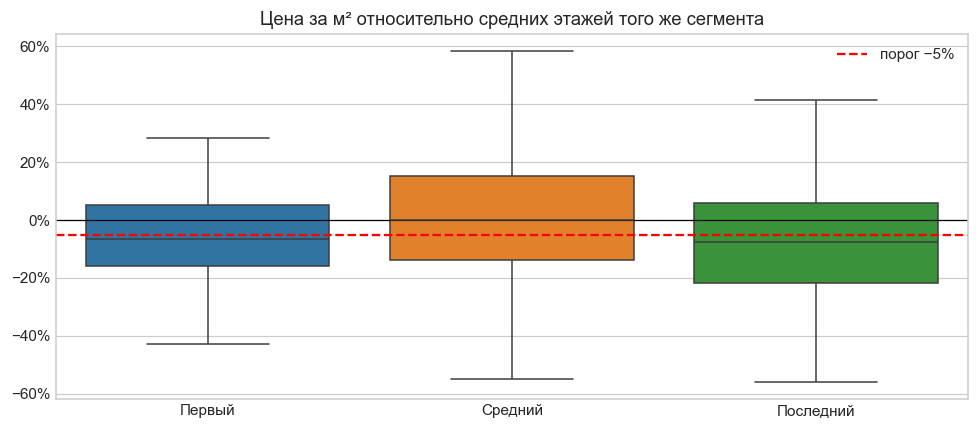

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
order = ["Первый", "Средний", "Последний"]
sns.boxplot(data=s.assign(floor_type=lambda x: pd.Categorical(x["floor_type"], order)),
            x="floor_type", y="rel", hue="floor_type", legend=False, showfliers=False, ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(-0.05, color="red", ls="--", label="порог −5%")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Цена за м² относительно средних этажей того же сегмента", xlabel="", ylabel="")
ax.legend()
plt.tight_layout(); plt.show()

**Вывод по H3 — подтверждается, но на границе.**
- Дисконт крайних этажей **есть и статистически значим**: первый этаж дешевле средних того же сегмента
  на **≈6,5%**, последний — на **≈7,5%**, вместе — на **≈7,1%** (95% ДИ: от 4,1% до 10,4%), p-value ≪ 0,001.
- **Порог «больше 5%»** подтверждается сдвинутым U-тестом: p ≈ 0,013 — меньше и 0,05, и порога с поправкой
  Бонферрони (≈0,017), но с минимальным запасом. При этом нижняя граница бутстрэп-интервала для разницы медиан
  (≈4%) чуть ниже 5%: U-тест сравнивает распределения целиком, а интервал — только медианы, поэтому
  на самой границе они дают немного разные ответы.
- Регрессия (этап 6) даёт похожие оценки: −6,1% для первого и −7,6% для последнего этажа при прочих равных.
- Честная формулировка: **крайние этажи дешевле в среднем на 6–8%; дисконт больше 5% подтверждается,
  но запас небольшой.** Квартир на первом этаже в выборке мало (90), поэтому оценка для них менее точная.

**Что делать бизнесу:** использовать дисконт 6–8% как аргумент в торге при покупке крайних этажей.
Для инвестора это плюс: арендатор платит за крайний этаж почти столько же, а покупка обходится дешевле.

## Сводка

In [7]:
summary = pd.DataFrame(results)
summary["H₀ отвергнута (α=0,05)"] = summary["p-value"] < ALPHA
summary["с поправкой Бонферрони"] = summary["p-value"] < ALPHA_BONF
summary.to_csv("data/hypotheses_results.csv", index=False, encoding="utf-8-sig")
summary.style.format({"медиана A": "{:.2%}", "медиана B": "{:.2%}", "разница медиан": "{:+.2%}",
                      "ДИ 95% низ": "{:+.2%}", "ДИ 95% верх": "{:+.2%}", "p-value": "{:.1e}"})

,гипотеза,группа A,n A,медиана A,группа B,n B,медиана B,разница медиан,ДИ 95% низ,ДИ 95% верх,p-value,"H₀ отвергнута (α=0,05)",с поправкой Бонферрони
0,H1,1-комнатные,627,9.34%,3-комнатные,915,7.82%,+1.52%,+1.25%,+1.88%,1.6e-42,True,True
1,H2,Правый берег,1087,9.26%,Левый берег,1791,8.05%,+1.21%,+0.97%,+1.37%,4.6e-39,True,True
2,H3 (первый),Первый,90,-6.49%,Средний,2230,0.00%,-6.49%,-10.08%,-2.06%,2.5e-03,True,True
3,H3 (последний),Последний,283,-7.45%,Средний,2230,0.00%,-7.45%,-11.89%,-4.07%,1.3e-09,True,True
4,H3 (крайние вместе),Крайние,373,-7.11%,Средний,2230,0.00%,-7.11%,-10.42%,-4.12%,7.8e-11,True,True


| Гипотеза | Результат | Эффект | Решение для агентства |
|---|---|---|---|
| **H1.** Однушки доходнее трёшек | ✅ **Подтверждена** | +1,5 п.п. чистой доходности, в каждом районе | По умолчанию предлагать однушки; «две однушки вместо трёшки» |
| **H2.** Правый берег доходнее левого | ✅ **Подтверждена** | +1,2 п.п., в каждой группе комнат | Правый берег — клиентам, которым важна окупаемость |
| **H3.** Крайние этажи дешевле на 5%+ | ✅ **Подтверждена (на границе)** | дисконт 6–8%; порог 5% проходит с небольшим запасом | Аргумент в торге; учитывать при оценке доходности |